# MFCK – validation of `predict_level_covariances`

Two-fidelity Sasena (2002) test case. Figures check that the posterior covariance
between fidelity levels is consistent with `predict_variances`, and that the
LF/HF correlation vanishes wherever a level is already sampled.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---- shared figure style (identical for every figure) ----------------------
# Colours are tied to entities, never to rank: LF = orange, HF = blue,
# cross-level quantity (LF/HF) = aqua.
C_LF, C_HF, C_X = "#eb6834", "#2a78d6", "#1baf7a"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "lines.linewidth": 1.1,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "legend.frameon": True,
    "legend.framealpha": 0.75,
    "legend.facecolor": "white",
    "legend.edgecolor": GRID,
    "legend.fancybox": False,
    "legend.borderpad": 0.4,
    "legend.fontsize": 8,
    "figure.constrained_layout.use": True,
})
PANEL_W, PANEL_H = 5.2, 4.0      # size of one panel, same for every figure


def new_figure(ncols=1, suptitle=None):
    fig, axes = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H), squeeze=False)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, fontweight="bold")
    return fig, axes.ravel()


def finish_axis(ax, title, xlabel="Input $x$", ylabel=None, legend=True, ncol=2):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_xlim(bounds[0, 0], bounds[0, 1])
    if legend:
        # reserve a free band at the top of the axes for the legend, so that it
        # sits inside the plot (on a translucent background) without hiding data
        n = len(ax.get_legend_handles_labels()[0])
        rows = -(-n // ncol)
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (0.07 * rows + 0.04) * (hi - lo))
        ax.legend(loc="upper center", ncol=ncol)


def plot_samples(ax, y_fn=True):
    """HF/LF training samples, same markers in every figure that shows them."""
    ax.scatter(xt[0], yt[0], marker="o", s=26, color=C_LF, edgecolor="white",
               linewidth=0.5, zorder=4, label="LF samples")
    ax.scatter(xt[1], yt[1], marker="s", s=30, color=C_HF, edgecolor="white",
               linewidth=0.5, zorder=5, label="HF samples")


def plot_sample_locations(ax):
    """Vertical guides at the sampled inputs (for figures without y data)."""
    for k, (x, c, name) in enumerate(zip(xt, (C_LF, C_HF), ("LF", "HF"))):
        for j, xi in enumerate(x):
            ax.axvline(xi, color=c, lw=0.7, ls=":", alpha=0.7,
                       label=f"{name} sample locations" if j == 0 else None)

## 1. Test problem and training data

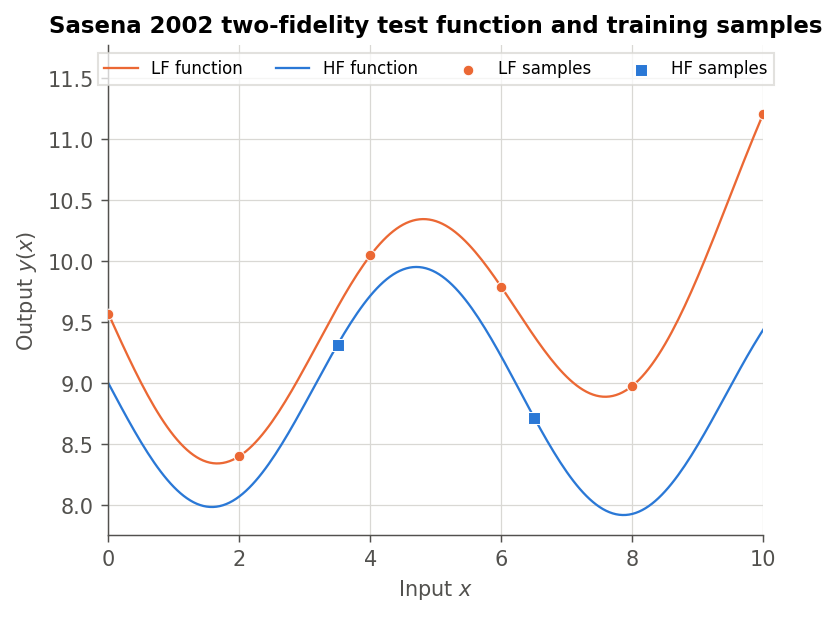

In [2]:
# high-fidelity function
def sasena2002_hf(x):
    return -np.sin(x) - np.exp(x / 100) + 10

# low-fidelity function
def sasena2002_lf(x):
    return sasena2002_hf(x) + 0.3 + 0.03 * (x - 3) ** 2

bounds = np.array([[0, 10]])

x_valid = np.linspace(bounds[0, 0], bounds[0, 1], 201)
X_valid = x_valid.reshape(-1, 1)
y_hf = sasena2002_hf(x_valid)
y_lf = sasena2002_lf(x_valid)

functions = [sasena2002_lf, sasena2002_hf]

xt = [
    np.array([0., 2, 4, 6, 8, 10]),   # LF samples
    np.array([3.5, 6.5]),             # HF samples
]
yt = [f(x) for f, x in zip(functions, xt)]

fig, (ax,) = new_figure()
ax.plot(x_valid, y_lf, color=C_LF, label="LF function")
ax.plot(x_valid, y_hf, color=C_HF, label="HF function")
plot_samples(ax)
finish_axis(ax, "Sasena 2002 two-fidelity test function and training samples",
            ylabel="Output $y(x)$", ncol=4)
plt.show()

## 2. Train the MFCK model

In [3]:
from smt.applications import MFCK

sm = MFCK(print_global=False, hyper_opt="Cobyla", n_start=3)

sm.set_training_values(xt[0].reshape(-1, 1), yt[0].reshape(-1, 1), name=0)
sm.set_training_values(xt[1].reshape(-1, 1), yt[1].reshape(-1, 1))

sm.train()

## 3. HF prediction uncertainty: `predict_variances` vs `predict_level_covariances`

For the highest level, `predict_level_covariances(X, 1, 1)` must reproduce
`predict_variances(X)`. Panels (a) and (b) show the $\pm 1\sigma$ band obtained
from each method; panel (c) overlays the two variances.

max |difference| between the two variances: 0.0


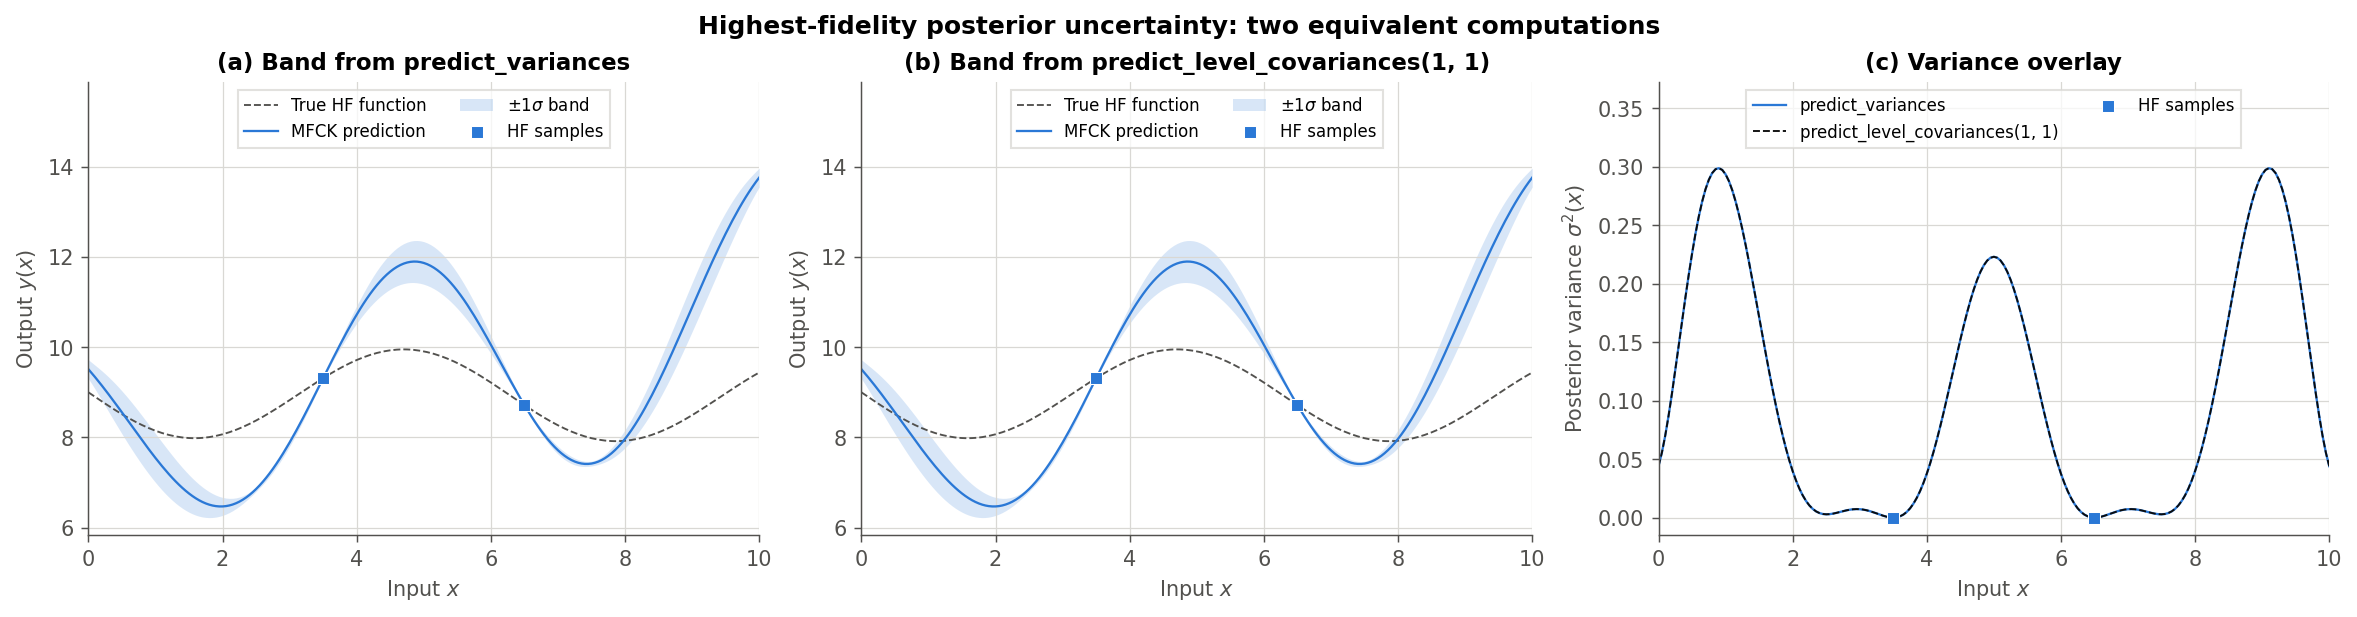

In [4]:
y_pred = sm.predict_values(X_valid).ravel()
s2_var = sm.predict_variances(X_valid).ravel()
s2_cov = sm.predict_level_covariances(X_valid, lvli=1, lvlj=1).ravel()

fig, ax = new_figure(3, "Highest-fidelity posterior uncertainty: two equivalent computations")

for a, s2, title in (
    (ax[0], s2_var, "(a) Band from predict_variances"),
    (ax[1], s2_cov, "(b) Band from predict_level_covariances(1, 1)"),
):
    sd = np.sqrt(np.clip(s2, 0, None))
    a.plot(x_valid, y_hf, color=INK_2, ls="--", lw=0.9, label="True HF function")
    a.plot(x_valid, y_pred, color=C_HF, label="MFCK prediction")
    a.fill_between(x_valid, y_pred - sd, y_pred + sd, color=C_HF, alpha=0.18,
                   linewidth=0, label=r"$\pm 1\sigma$ band")
    a.scatter(xt[1], yt[1], marker="s", s=30, color=C_HF, edgecolor="white",
              linewidth=0.5, zorder=5, label="HF samples")
    finish_axis(a, title, ylabel="Output $y(x)$")

ax[1].sharey(ax[0])
ax[2].plot(x_valid, s2_var, color=C_HF, label="predict_variances")
ax[2].plot(x_valid, s2_cov, color=INK, ls="--", lw=0.9,
           label="predict_level_covariances(1, 1)")
ax[2].scatter(xt[1], np.zeros_like(xt[1]), marker="s", s=30, color=C_HF,
              edgecolor="white", linewidth=0.5, zorder=5, clip_on=False,
              label="HF samples")
finish_axis(ax[2], "(c) Variance overlay", ylabel=r"Posterior variance $\sigma^2(x)$")
print("max |difference| between the two variances:", np.max(np.abs(s2_var - s2_cov)))
plt.show()

## 4. Covariances and correlation between fidelity levels

Left: posterior (co)variances of the latent LF and HF functions. Right: the
correlation $\rho(x) = \mathrm{cov}_{01}(x)\,/\,\sqrt{\mathrm{cov}_{00}(x)\,\mathrm{cov}_{11}(x)}$,
set to 0 where either variance is numerically zero (below $10^{-8}$). It must
vanish at every location where the LF or the HF level is already sampled; the
markers in panel (b) show $\rho_{10}$ evaluated exactly at those inputs. Between
samples $\rho_{10}$ can take either sign, and approaches $\pm 1$ right next to a
sampled input, where both residual uncertainties are driven by the same data.

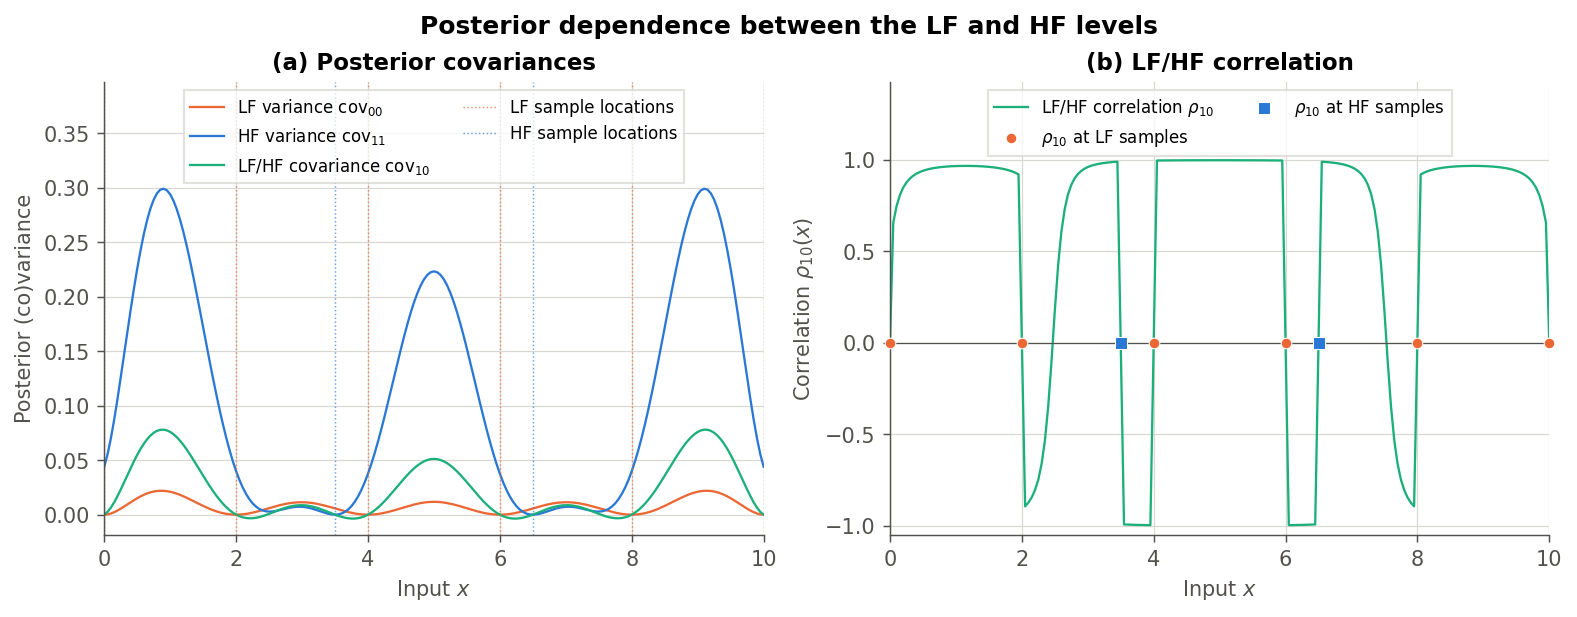

In [5]:
def level_correlation(X, eps=1e-8):
    """rho(x) = cov_10 / sqrt(cov_00 cov_11); set to 0 where a variance is below eps."""
    c00 = sm.predict_level_covariances(X, lvli=0, lvlj=0).ravel()
    c10 = sm.predict_level_covariances(X, lvli=1, lvlj=0).ravel()
    c11 = sm.predict_level_covariances(X, lvli=1, lvlj=1).ravel()
    ok = (c00 > eps) & (c11 > eps)
    rho = np.zeros_like(c10)
    rho[ok] = c10[ok] / np.sqrt(c00[ok] * c11[ok])
    return c00, c10, c11, np.clip(rho, -1, 1)


cov_00, cov_10, cov_11, corr_10 = level_correlation(X_valid)
# correlation evaluated exactly at the sampled inputs
rho_lf = level_correlation(xt[0].reshape(-1, 1))[-1]
rho_hf = level_correlation(xt[1].reshape(-1, 1))[-1]

fig, ax = new_figure(2, "Posterior dependence between the LF and HF levels")

ax[0].plot(x_valid, cov_00, color=C_LF, label=r"LF variance $\mathrm{cov}_{00}$")
ax[0].plot(x_valid, cov_11, color=C_HF, label=r"HF variance $\mathrm{cov}_{11}$")
ax[0].plot(x_valid, cov_10, color=C_X, label=r"LF/HF covariance $\mathrm{cov}_{10}$")
plot_sample_locations(ax[0])
finish_axis(ax[0], "(a) Posterior covariances", ylabel="Posterior (co)variance")

ax[1].plot(x_valid, corr_10, color=C_X, label=r"LF/HF correlation $\rho_{10}$")
ax[1].scatter(xt[0], rho_lf, marker="o", s=26, color=C_LF, edgecolor="white",
              linewidth=0.5, zorder=4, clip_on=False, label=r"$\rho_{10}$ at LF samples")
ax[1].scatter(xt[1], rho_hf, marker="s", s=30, color=C_HF, edgecolor="white",
              linewidth=0.5, zorder=5, clip_on=False, label=r"$\rho_{10}$ at HF samples")
ax[1].axhline(0, color=INK_2, lw=0.6)
ax[1].set_ylim(-1.05, 1.05)
finish_axis(ax[1], "(b) LF/HF correlation", ylabel=r"Correlation $\rho_{10}(x)$")
plt.show()